# Встреча 5. Где обычный A/B ломается: теория

> **Время:** 35 минут · **Дальше:** `practice.ipynb`

Обычный A/B держится на трёх допущениях: единицы независимы, назначение случайно, исход единицы зависит только от её собственного назначения (SUTVA). В оффлайне, на маркетплейсах и в логистике ломается хотя бы одно. Разберём, что именно ломается и какой дизайн это чинит.

| Блок | Тезис | Минут |
| --- | --- | :---: |
| 1 | Единица в оффлайне: недели одного магазина — почти одно наблюдение (ICC и дизайн-эффект) | 12 |
| 2 | Пилот в оффлайне: мощность покупается магазинами, смещение от отбора не лечится ни объёмом, ни матчингом | 12 |
| 3 | Интерференция и switchback: где SUTVA врёт, carryover и выбор окна | 11 |

### Библиотеки

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
ALPHA = 0.05
Z = stats.norm.ppf(1 - ALPHA / 2)

## Блок 1. Единица в оффлайне: ICC и дизайн-эффект (12 минут)

**Тезис.** Если воздействие назначено магазину, то 12 недель одного магазина — не 12 наблюдений. Они делят общий уровень магазина: размер, локацию, трафик. Сколько в них независимой информации, говорит ICC.

Модель: недельная метрика магазина $j$ в неделю $i$

$$
Y_{ij} = \mu + u_j + e_{ij}, \qquad \rho = \text{ICC} = \frac{\sigma_u^2}{\sigma_u^2 + \sigma_e^2}.
$$

$\rho$ — доля дисперсии, которая приходится на различия **между** магазинами, и одновременно корреляция двух недель одного магазина. Среднее по $m$ неделям магазина имеет дисперсию $\frac{\sigma^2}{m}\,(1 + (m-1)\rho)$. Множитель

$$
DE = 1 + (m - 1)\,\rho
$$

— **дизайн-эффект**: во столько раз реальная дисперсия больше той, что считает тест «строки независимы». Эффективный размер выборки — $n / DE$.

Посмотрим, каков ICC в нашей сети магазинов (лог недельной выручки, 40 недель до пилота).

In [2]:
panel = pd.read_csv('../data/store_panel.csv', parse_dates=['week'])
Y = np.log(panel.pivot(index='week', columns='store', values='sales')).to_numpy()[:40]
between = Y.mean(axis=0).var()
within = (Y - Y.mean(axis=0)).var()
rho_shop = between / (between + within)
de_12 = 1 + 11 * rho_shop
print(f"Дисперсия между магазинами {between:.4f}, внутри магазина {within:.4f}")
print(f"ICC = {rho_shop:.2f}; для 12 недель DE = {de_12:.1f}: 300 магазинов × 12 недель = 3 600 строк ≈ {3600 / de_12:.0f} независимых")

Дисперсия между магазинами 0.1431, внутри магазина 0.0096
ICC = 0.94; для 12 недель DE = 11.3: 300 магазинов × 12 недель = 3 600 строк ≈ 318 независимых


**ICC 0.94.** Различия между магазинами в 15 раз больше колебаний недель внутри магазина: дисперсия 0.143 против 0.0096. При 12 неделях $DE = 11.3$: 3 600 магазино-недель весят как ~318 независимых наблюдений, почти одно на магазин.

Что будет, если этого не заметить и сделать t-тест по строкам? Тест занижает дисперсию в $DE$ раз, поэтому на A/A срабатывает с вероятностью $2\,\Phi\!\left(-z_{1-\alpha/2}/\sqrt{DE}\right)$ вместо 5%. Проверим формулу симуляцией: 40 кластеров, две половины, эффекта нет.

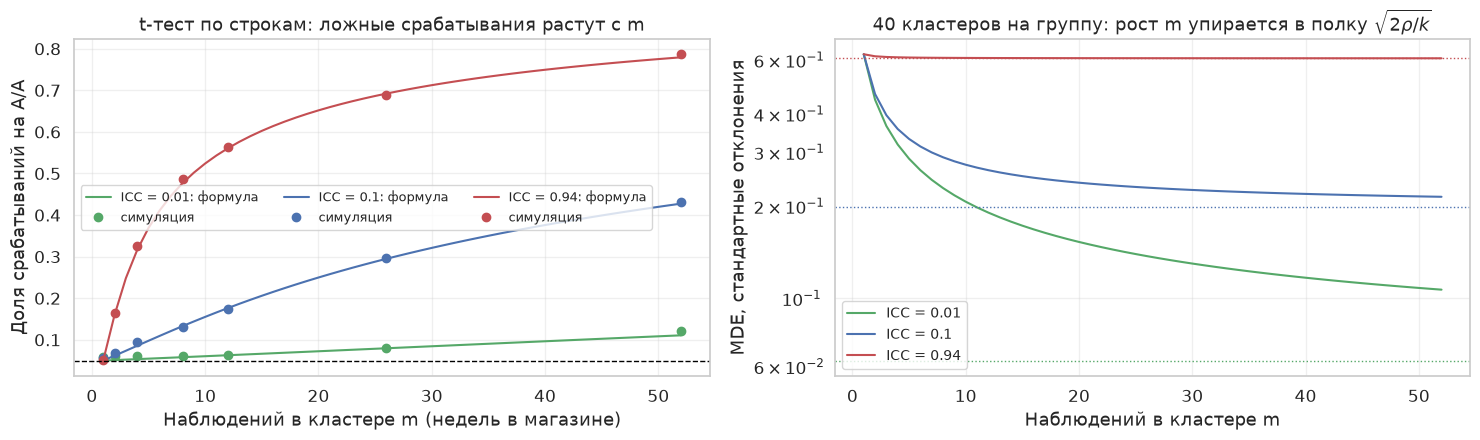

ICC 0.94, 12 недель: формула 56%, симуляция 56%


In [3]:
def naive_fpr_sim(rho: float, m: int, k: int = 40, reps: int = 4000, seed: int = 1) -> float:
    # A/A: k кластеров по m наблюдений, t-тест по наблюдениям, будто они независимы
    rng = np.random.default_rng(seed)
    u = rng.normal(0, np.sqrt(rho), (reps, k, 1))
    e = rng.normal(0, np.sqrt(1 - rho), (reps, k, m))
    y = (u + e).reshape(reps, k, m)
    a, b = y[:, :k // 2].reshape(reps, -1), y[:, k // 2:].reshape(reps, -1)
    t = (a.mean(1) - b.mean(1)) / np.sqrt(a.var(1, ddof=1) / a.shape[1] + b.var(1, ddof=1) / b.shape[1])
    return np.mean(np.abs(t) > Z)


def naive_fpr_formula(rho, m):
    return 2 * stats.norm.sf(Z / np.sqrt(1 + (np.asarray(m) - 1) * rho))


def cluster_mde(k, m, rho, power=0.8):
    # MDE в стандартных отклонениях: k кластеров на группу по m наблюдений
    return (Z + stats.norm.ppf(power)) * np.sqrt(2 * (1 + (np.asarray(m) - 1) * rho) / (k * np.asarray(m)))


ms = np.array([1, 2, 4, 8, 12, 26, 52])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for rho, color in [(0.01, GREEN), (0.1, BLUE), (round(rho_shop, 2), RED)]:
    grid = np.arange(1, 53)
    axes[0].plot(grid, naive_fpr_formula(rho, grid), color=color, label=f'ICC = {rho}: формула')
    axes[0].plot(ms, [naive_fpr_sim(rho, m) for m in ms], 'o', color=color, label='симуляция')
    axes[1].plot(grid, cluster_mde(40, grid, rho), color=color, label=f'ICC = {rho}')
    axes[1].axhline(cluster_mde(40, 1e9, rho), color=color, linestyle=':', linewidth=1)
axes[0].axhline(ALPHA, color='black', linestyle='--', linewidth=1)
axes[0].set(xlabel='Наблюдений в кластере m (недель в магазине)', ylabel='Доля срабатываний на A/A',
            title='t-тест по строкам: ложные срабатывания растут с m')
axes[0].legend(fontsize=9, ncol=3)
axes[1].set(xlabel='Наблюдений в кластере m', ylabel='MDE, стандартные отклонения', yscale='log',
            title='40 кластеров на группу: рост m упирается в полку $\\sqrt{2\\rho/k}$')
axes[1].legend(fontsize=10)
plt.tight_layout(); plt.show()
print(f"ICC {rho_shop:.2f}, 12 недель: формула {naive_fpr_formula(rho_shop, 12):.0%}, симуляция {naive_fpr_sim(rho_shop, 12):.0%}")

Формула совпала с симуляцией: при ICC 0.94 и 12 неделях наивный тест срабатывает в **56%** A/A. Даже ICC 0.01, который выглядит пренебрежимым, при 52 наблюдениях в кластере даёт 11% вместо 5%. Справа видно, что при большом ICC MDE с первых же недель упирается в полку $\sqrt{2\rho/k}$. Новые недели почти ничего не дают, сдвинуть полку можно только числом кластеров.

**Почему недели в магазине не независимы — даже после вычитания уровня.** DiD убирает $u_j$, но не всё: у магазинов бывают собственные тренды и медленные сдвиги (ремонт, конкурент рядом, смена директора). Это автокорреляция остатков, и DiD по магазино-неделям с обычными ошибками тоже ошибается чаще 5% (Bertrand, Duflo, Mullainathan, 2004). Рецепт одинаковый:

* **единица анализа = единица рандомизации** — одно число на магазин (среднее или изменение), тест по магазинам;
* или кластеризованные ошибки по магазину; при малом числе кластеров — рандомизационный тест.

Мощность при этом определяет **число кластеров**: полка $\sqrt{2\rho/k}$ сдвигается только ростом $k$.

## Блок 2. Пилот в оффлайне (12 минут)

**Тезис.** Магазинов мало, они разные, а список пилотных часто составляет бизнес. Поэтому основная работа делается до старта:

1. **Отбор пула** — только магазины, где изменение физически возможно и данные полные (без закрытий и ремонтов).
2. **Пары** — похожие магазины объединяем в пары, внутри пары монеткой выбираем пилотный. Пары страхуют от неудачного разбиения и дают понятный анализ.
3. **Мощность инъекцией** — вместо формулы: берём историю, случайные окна и группы, считаем оценку; её разброс даёт MDE; добавляем известный эффект и смотрим, как часто метод его находит.
4. **DiD** — сравниваем не уровни, а изменения: $\Delta_i = \bar y_i^{\text{после}} - \bar y_i^{\text{до}}$. Магазин — сам себе контроль, постоянные различия вычитаются.
5. **Плацебо по датам** — тот же расчёт на окнах до старта. Если «эффект» есть там, где воздействия не было, — метод смещён.

DiD держится на **параллельных трендах**: без пилота группы менялись бы одинаково. Случайное назначение это гарантирует в среднем, выбор бизнеса — нет.

Симуляция: 200 магазинов, у каждого свой уровень и свой небольшой тренд, 40 недель истории. Пилот — 30 магазинов, 12 недель, эффект +3%. Сравним четыре способа: случайно + разность уровней, случайно + DiD, пары + DiD и «бизнес выбрал растущие» + DiD, а для последнего — плацебо.

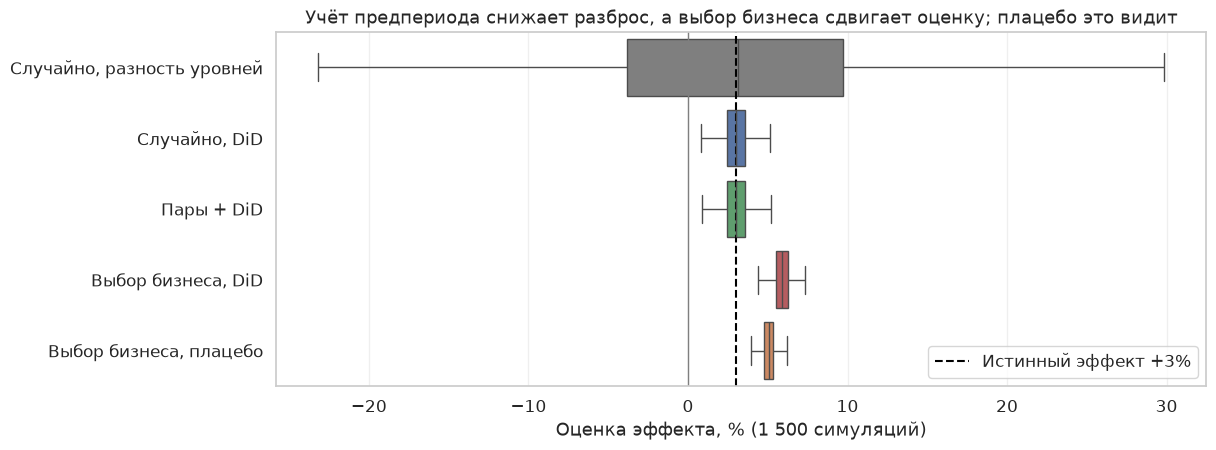

,"Среднее, %","Разброс, %"
"Случайно, разность уровней",2.97,10.29
"Случайно, DiD",2.99,0.81
Пары + DiD,3.03,0.83
"Выбор бизнеса, DiD",5.88,0.56
"Выбор бизнеса, плацебо",5.06,0.43


In [4]:
def toy_panel(rng, n=200, weeks=40):
    level = rng.normal(0, 0.4, n)
    slope = rng.normal(0, 0.002, n)                   # у магазинов свои тренды
    t = np.arange(weeks)[:, None]
    return level + slope * t + rng.normal(0, 0.05, (weeks, n)), slope


def pilot_estimates(reps=1500, k=30, effect=0.03, t0=28, pre=12, post=12, seed=3):
    rng = np.random.default_rng(seed)
    out = {name: [] for name in ['Случайно, разность уровней', 'Случайно, DiD', 'Пары + DiD',
                                 'Выбор бизнеса, DiD', 'Выбор бизнеса, плацебо']}
    for _ in range(reps):
        y, slope = toy_panel(rng)
        n = y.shape[1]
        delta = lambda m, s: m[s:s + post].mean(0) - m[s - pre:s].mean(0)

        def did(treated, start, lift):
            m = y.copy(); m[start:start + post, treated] += lift
            d = delta(m, start); mask = np.zeros(n, bool); mask[treated] = True
            return d[mask].mean() - d[~mask].mean()

        # случайно: 2k магазинов, половина в пилот (столько же, сколько в парах)
        sample = rng.choice(n, 2 * k, replace=False)
        tr, ct = sample[:k], sample[k:]
        m = y.copy(); m[t0:t0 + post, tr] += effect
        out['Случайно, разность уровней'].append(m[t0:t0 + post, tr].mean() - m[t0:t0 + post, ct].mean())
        d = delta(m, t0)
        out['Случайно, DiD'].append(d[tr].mean() - d[ct].mean())
        # пары по уровню до старта: соседей по уровню объединяем, монетка внутри пары
        order = np.argsort(y[t0 - pre:t0].mean(0))
        pairs = order.reshape(-1, 2)[rng.choice(n // 2, k, replace=False)]
        coin = rng.integers(0, 2, k)
        tr, ct = pairs[np.arange(k), coin], pairs[np.arange(k), 1 - coin]
        m = y.copy(); m[t0:t0 + post, tr] += effect
        d = delta(m, t0)
        out['Пары + DiD'].append((d[tr] - d[ct]).mean())
        # бизнес выбирает магазины, которые «растут»: наибольший наклон по истории до старта
        growth = np.polyfit(np.arange(t0), y[:t0], 1)[0]
        chosen = np.argsort(-growth)[:k]
        out['Выбор бизнеса, DiD'].append(did(chosen, t0, effect))
        out['Выбор бизнеса, плацебо'].append(did(chosen, t0 - 14, 0.0))
    return pd.DataFrame(out)


est = pilot_estimates()
fig, ax = plt.subplots(figsize=(12, 4.6))
colors = [GRAY, BLUE, GREEN, RED, ORANGE]
sns.boxplot(data=est * 100, orient='h', palette=colors, ax=ax, showfliers=False)
ax.axvline(3, color='black', linestyle='--', label='Истинный эффект +3%')
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlabel('Оценка эффекта, % (1 500 симуляций)')
ax.set_title('Учёт предпериода снижает разброс, а выбор бизнеса сдвигает оценку; плацебо это видит')
ax.legend(loc='lower right')
plt.show()
table = pd.DataFrame({'Среднее, %': est.mean() * 100, 'Разброс, %': est.std() * 100}).round(2)
table

Что видно на графике:

* **Без учёта предпериода** разброс оценки 10.3%: эффект +3% тонет в различиях между магазинами.
* **DiD** снижает разброс до 0.8%, в 13 раз: уровень магазина вычитается.
* **Пары поверх DiD** почти ничего не добавляют (0.83%): они выравнивают уровень, который DiD уже убрал. Их польза в другом — страховка от неудачного разбиения при 5–10 магазинах и понятный бизнесу анализ «каждому пилотному свой контрольный».
* **Выбор бизнеса** («ставим туда, где растёт») даёт +5.9% вместо +3%. Смещение 2.9 п.п. при разбросе 0.56%: интервал уверенно не накрывает правду.
* **Плацебо** на окне до старта показывает +5.1% там, где воздействия не было. Это даже больше смещения: магазины отбирали по тем же неделям, и к тренду добавился подобранный шум. Сигнал однозначный: оценке верить нельзя. Общее правило: окно плацебо не должно пересекаться с неделями, по которым что-то подбирали (список магазинов, пары, веса). Внутри окна отбора плацебо раздуто, внутри окна подбора пар — занижено.

Что взять в практику:

* **Мощность покупается магазинами, а не неделями.** Шум магазина состоит из быстрой части, которая усредняется, и медленной (тренд, дрейф), которая не усредняется. После нескольких недель MDE почти не падает.
* **Смещение от отбора не уменьшается от роста выборки** и не лечится матчингом по уровню: матчинг выравнивает то, что видно до старта, а смещение приходит из динамики.
* **Плацебо по датам** — обязательная проверка любого квазиэксперимента. Если оно не ноль, оценку нельзя докладывать. Обратное неверно: плацебо около нуля не доказывает, что смещения нет в окне пилота. Оно проверяет только прошлое.
* **Если отбор уже случился,** смещение от разницы в росте можно снять поправкой на тренд, проведённый по истории (в практике). Это не рандомизация, а допущение: тренд линейный и продолжается в окне пилота.

**Когда рандомизация невозможна совсем.** Один-два тестовых региона, ТВ, наружка — тогда **geo-эксперимент** с парами регионов и регрессией на историю (GBR, TBR, Trimmed Match) или **синтетический контроль**: взвешенная смесь контрольных единиц повторяет кривую теста до старта. Его ограничение — смесь не выходит за пределы доноров: если тест растёт быстрее всех контрольных, синтетика его не догонит. Проверка та же — плацебо по датам и по донорам.

## Блок 3. Интерференция и switchback (11 минут)

**Тезис.** SUTVA требует, чтобы исход единицы зависел только от её собственного назначения: $Y_i(Z_1, \dots, Z_n) = Y_i(Z_i)$. На двусторонних рынках это неверно: тестовые заказы и контрольные делят **общий ресурс** — курьеров, водителей, товарный остаток. Тест забирает ресурс у контроля, и A/B видит разницу, которой при полном внедрении не будет. Это не шум, а **смещение**: оно не уменьшается от роста выборки.

Симуляция: зона в течение часа, 200 клиентов, курьеров — случайное число около заданного уровня. Новая механика повышает долю клиентов, готовых заказать, с 60% до 72%. Заказов больше, чем курьеров, — лишние не выполняются, а выполненные делятся между группами случайно.

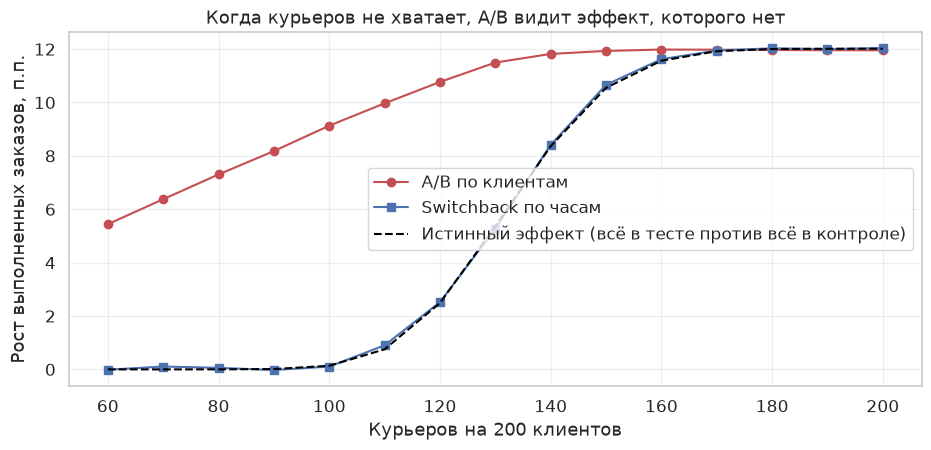

,Истинный эффект,A/B по клиентам,Switchback по часам
80,0.0,7.3,0.1
120,2.5,10.8,2.5
160,11.6,12.0,11.6
200,12.0,12.0,12.0


In [5]:
def market_hour(n_clients, n_test, couriers, rng, p_control=0.60, p_test=0.72):
    demand_test = rng.binomial(n_test, p_test)
    demand_control = rng.binomial(n_clients - n_test, p_control)
    done = np.minimum(demand_test + demand_control, couriers)
    done_test = rng.hypergeometric(demand_test, demand_control, done)
    return done_test, done - done_test


def interference(supply, hours=20_000, n=200, seed=1):
    rng = np.random.default_rng(seed)
    clients, couriers = np.full(hours, n), rng.poisson(supply, hours)
    all_test, _ = market_hour(clients, clients, couriers, rng)
    _, all_control = market_hour(clients, np.zeros(hours, int), couriers, rng)
    half = np.full(hours, n // 2)
    t, c = market_hour(clients, half, couriers, rng)
    switch = rng.integers(0, 2, hours).astype(bool)
    st, sc = market_hour(clients, switch * n, couriers, rng)
    total = st + sc
    return {'Истинный эффект': (all_test.mean() - all_control.mean()) / n,
            'A/B по клиентам': (t.mean() - c.mean()) / (n // 2),
            'Switchback по часам': (total[switch].mean() - total[~switch].mean()) / n}


supply_grid = np.arange(60, 201, 10)
curves = pd.DataFrame([interference(s) for s in supply_grid], index=supply_grid)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(curves.index, 100 * curves['A/B по клиентам'], 'o-', color=RED, label='A/B по клиентам')
ax.plot(curves.index, 100 * curves['Switchback по часам'], 's-', color=BLUE, label='Switchback по часам')
ax.plot(curves.index, 100 * curves['Истинный эффект'], '--', color='black', label='Истинный эффект (всё в тесте против всё в контроле)')
ax.set(xlabel='Курьеров на 200 клиентов', ylabel='Рост выполненных заказов, п.п.',
       title='Когда курьеров не хватает, A/B видит эффект, которого нет')
ax.legend(); plt.show()
(100 * curves.loc[[80, 120, 160, 200]]).round(1)

При 80 курьерах на 200 клиентов истинный эффект равен нулю: всё упирается в курьеров. A/B показывает **+7.3 п.п.**: тест просто забирает курьеров у контроля. При 120 курьерах истина 2.5 п.п., A/B — 10.8. Switchback попадает в истину (0.1 и 2.5). Когда курьеров с запасом (160 и больше), интерференции нет, и оба метода совпадают.

**Switchback** рандомизирует не клиента, а **зону × окно времени**: всё окно целиком в тесте или в контроле. Внутри окна интерференции между группами нет. Цена — два новых вопроса.

* **Carryover.** После переключения система не сразу приходит в новый режим: курьеры перераспределяются, очередь заказов рассасывается. Если перенос длится $m$ часов, а окно — $w$, то без отбрасывания первые часы окна смешивают режимы. При случайном переключении (вероятность смены 1/2) смещение примерно $-\tau\,\frac{m}{2w}$ при $w \ge m$: окно 3 часа при $m = 2$ теряет треть эффекта.
* **Окно.** Короткое окно — много рандомизаций и маленькая дисперсия, но большой перенос (bias). Длинное — перенос пренебрежим, но независимых окон мало, и дисперсия растёт. Стандартный компромисс: окно в несколько длительностей переноса, первые $m$ часов каждого окна **отбрасываем** (burn-in).
* **Анализ.** Единица — эпоха (зона × окно), а не заказ и не час. t-тест по часам на A/A срабатывает тем чаще, чем длиннее окно: окно — это кластер, и его дизайн-эффект $1 + (w-1)\rho$. Проверка — A/A по эпохам на истории, как в практике.

In [6]:
m_carry, tau = 2, 1.0
w = np.array([2, 3, 4, 6, 8, 12, 24])
print(pd.DataFrame({'Окно w, ч': w, 'Смещение без burn-in ≈ −τ·m/(2w), w ≥ m': (-tau * m_carry / (2 * w)).round(3),
                    'Доля данных, которую съедает burn-in m/w': (m_carry / w).round(2)}).to_string(index=False))

 Окно w, ч  Смещение без burn-in ≈ −τ·m/(2w), w ≥ m  Доля данных, которую съедает burn-in m/w
         2                                   -0.500                                      1.00
         3                                   -0.333                                      0.67
         4                                   -0.250                                      0.50
         6                                   -0.167                                      0.33
         8                                   -0.125                                      0.25
        12                                   -0.083                                      0.17
        24                                   -0.042                                      0.08


### Итог теории

| Ограничение | Что ломается | Дизайн | Проверка |
| --- | --- | --- | --- |
| Воздействие на магазин/регион/класс | независимость наблюдений | кластерный A/B, анализ по кластерам | A/A на истории, ICC и DE |
| Мало единиц, они разные | мощность | пары + DiD, мощность инъекцией | MDE по истории, A/A |
| Список выбрал бизнес | случайность назначения | DiD с матчингом и поправкой на тренд, синтетический контроль | плацебо по датам и донорам |
| Общий ресурс (курьеры, склад) | SUTVA | switchback, кластеры на графе | carryover, окно, A/A по эпохам |
| Рандомизация невозможна | всё сразу | geo-эксперимент, синтетический контроль | плацебо, сверка на прошлом |

Полная карта — артефакт встречи `design_map.md`; в практике заполним строки нашего кейса числами.